In [1]:
# Simulator from https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git

from dataclasses import dataclass


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


# -------------------------------------------------
# Sample Instruction Set
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R5", "R6"]),
    Instruction("I3", "R7", ["R1", "R4"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R7", "R8"]),
    Instruction("I6", "R12", ["R13", "R14"]),
]


# -------------------------------------------------
# Function to check dependency
# -------------------------------------------------

def has_dependency(inst1, inst2):
    """
    Returns True if inst2 depends on inst1.
    """

    # RAW dependency:
    # inst2 reads a register written by inst1
    if inst1.destination in inst2.sources:
        return True

    return False


# -------------------------------------------------
# Sequential Execution
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Check whether all previous dependencies
            # have already been completed

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Execute all independent instructions
        # in the same cycle

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Mark instructions as completed

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Dependency Analysis
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            if has_dependency(instructions[i], instructions[j]):

                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"(Register: {instructions[i].destination})"
                )

                found = True

    if not found:
        print("No dependencies found.")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print("      INSTRUCTION-LEVEL PARALLELISM SIMULATOR")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Show dependencies

    show_dependencies(instructions)

    # Sequential execution

    sequential_cycles = sequential_execution(instructions)

    # Parallel execution

    parallel_cycles = parallel_execution(instructions)

    # Calculate speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "ILP reduces execution cycles by allowing "
        "independent instructions to execute in parallel."
    )


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()




************************************************************
      INSTRUCTION-LEVEL PARALLELISM SIMULATOR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1 (Register: R1)
I3 depends on I2 (Register: R4)
I5 depends on I3 (Register: R7)
I5 depends on I4 (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R7 = R1 + R4)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R7 + R8)
Cycle 6: Executing I6 (R12 = R13 + R14)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

PERFORMANCE COMPARISON
Sequential Cycles : 6
ILP Cyc

       DETEKSI DEPENDENSI & DIAGRAM (RAW, WAR, WAW)

[1. RAW (Read After Write) - True Data Dependency]:
  - I2 depend pada I1 (Membaca Register: R1)


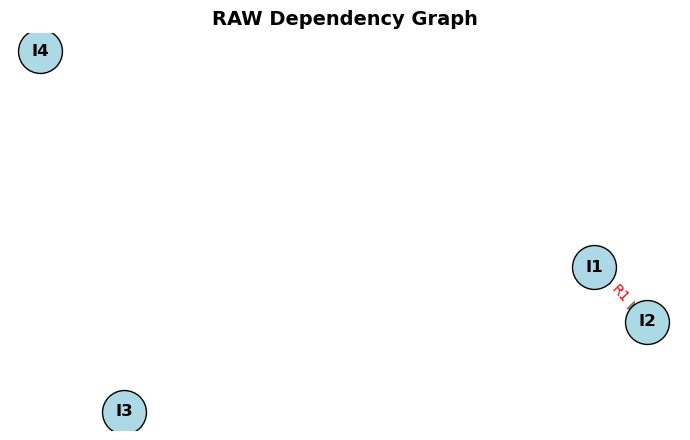


[2. WAR (Write After Read) - Anti-Dependency & Register Renaming]

-> Dependensi WAR Sebelum Renaming:
  - Hazard WAR: I3 menulis ke R2 yang sedang dibaca oleh I1
  - Hazard WAR: I4 menulis ke R1 yang sedang dibaca oleh I2

-> Menerapkan Register Renaming pada Instruksi yang Berkonflik:
  * I3: Register target 'R2' di-rename -> 'R2_renamed1'
  * I4: Register target 'R1' di-rename -> 'R1_renamed2'

-> Perbandingan Instruksi Sebelum vs Sesudah Renaming:
  I1: R1 = R2 + R3            ===>  I1: R1 = R2 + R3
  I2: R4 = R1 + R5            ===>  I2: R4 = R1 + R5
  I3: R2 = R6 + R7            ===>  I3: R2_renamed1 = R6 + R7
  I4: R1 = R8 + R9            ===>  I4: R1_renamed2 = R8 + R9

-> Dependensi WAR Sesudah Renaming: 0 dependensi.
   Kesimpulan: Hazard WAR berhasil dieliminasi sepenuhnya!


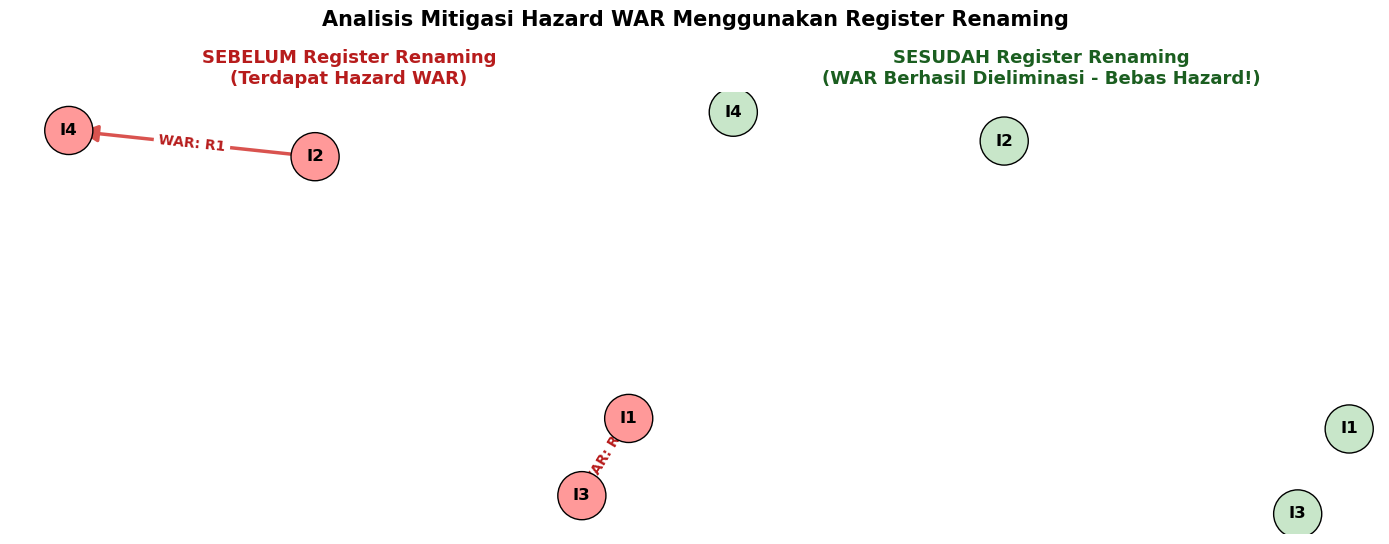



[3. WAW (Write After Write) - Output Dependency]:
  - I4 dan I1 sama-sama menulis ke Register: R1


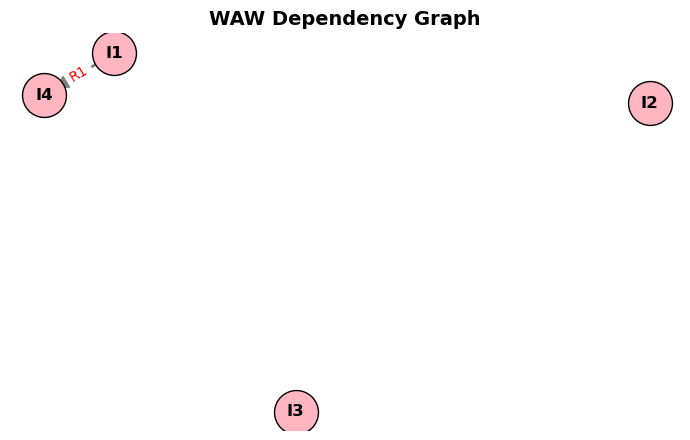

In [8]:
import matplotlib.pyplot as plt
import networkx as nx
from dataclasses import dataclass
import copy

@dataclass
class Instruction:
    name: str
    destination: str
    sources: list

# -------------------------------------------------
# Set Instruksi Baru (Memicu RAW, WAR, dan WAW sekaligus)
# -------------------------------------------------
instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),  # Menulis ke R1, membaca R2 dan R3
    Instruction("I2", "R4", ["R1", "R5"]),  # RAW pada R1 (I1 -> I2)
    Instruction("I3", "R2", ["R6", "R7"]),  # WAR pada R2 (I1 -> I3)
    Instruction("I4", "R1", ["R8", "R9"]),  # WAW pada R1 (I1 -> I4)
]

# -------------------------------------------------
# Dependency Checks (RAW, WAR, WAW)
# -------------------------------------------------

def get_raw_dependencies(instructions):
    """RAW (Read After Write): inst2 reads a register written by inst1 (inst1 -> inst2)"""
    dependencies = []
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            inst1, inst2 = instructions[i], instructions[j]
            if inst1.destination and inst1.destination in inst2.sources:
                dependencies.append((inst1.name, inst2.name, inst1.destination))
    return dependencies

def get_war_dependencies(instructions):
    """WAR (Write After Read): inst2 writes to a register read by inst1 (inst1 -> inst2)"""
    dependencies = []
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            inst1, inst2 = instructions[i], instructions[j]
            if inst2.destination and inst2.destination in inst1.sources:
                dependencies.append((inst1.name, inst2.name, inst2.destination))
    return dependencies

def get_waw_dependencies(instructions):
    """WAW (Write After Write): inst2 writes to a register written by inst1 (inst1 -> inst2)"""
    dependencies = []
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            inst1, inst2 = instructions[i], instructions[j]
            if inst1.destination == inst2.destination and inst1.destination is not None:
                dependencies.append((inst1.name, inst2.name, inst1.destination))
    return dependencies

# -------------------------------------------------
# Register Renaming untuk Mengeliminasi WAR
# -------------------------------------------------

def apply_register_renaming_for_war(instructions):
    """
    Mengeliminasi WAR hazard dengan mengubah register tujuan yang berkonflik
    (Register Renaming / Register Alias Table).
    """
    renamed = [copy.deepcopy(inst) for inst in instructions]
    renamed_registers = {}
    rename_counter = 1

    # Deteksi dependensi WAR
    war_deps = get_war_dependencies(renamed)

    for u_name, v_name, reg in war_deps:
        for idx in range(len(renamed)):
            # Temukan instruksi v (penulis baru) yang memicu WAR pada register tersebut
            if renamed[idx].name == v_name and renamed[idx].destination == reg and (v_name, reg) not in renamed_registers:
                new_reg = f"{reg}_renamed{rename_counter}"
                renamed_registers[(v_name, reg)] = new_reg
                renamed[idx].destination = new_reg
                rename_counter += 1

                # Perbarui instruksi berikutnya yang membaca hasil tulisan baru ini
                for k in range(idx + 1, len(renamed)):
                    if reg in renamed[k].sources:
                        renamed[k].sources = [new_reg if s == reg else s for s in renamed[k].sources]
                    # Hentikan jika register ditimpa kembali
                    if renamed[k].destination == reg:
                        break

    return renamed, renamed_registers

# -------------------------------------------------
# Dependency Graph Visualizations
# -------------------------------------------------

def plot_dependency_graph(instructions, dep_type, dependencies, color):
    G = nx.DiGraph()

    for inst in instructions:
        G.add_node(inst.name)

    edge_labels = {}
    for u, v, reg in dependencies:
        G.add_edge(u, v)
        edge_labels[(u, v)] = reg

    plt.figure(figsize=(7, 4.5))
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx_nodes(G, pos, node_size=1000, node_color=color, edgecolors='black')
    nx.draw_networkx_labels(G, pos, font_size=12, font_family='sans-serif', font_weight='bold')
    nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=20, edge_color='gray', width=2)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_color='red')

    plt.title(f"{dep_type} Dependency Graph", fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def plot_war_comparison(orig_instructions, renamed_instructions, war_before, war_after):
    """
    Menampilkan grafik perbandingan SEBELUM vs SESUDAH Register Renaming pada WAR.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    # 1. Graf Sebelum Renaming
    G_before = nx.DiGraph()
    for inst in orig_instructions:
        G_before.add_node(inst.name)

    edge_labels_before = {}
    for u, v, reg in war_before:
        G_before.add_edge(u, v)
        edge_labels_before[(u, v)] = f"WAR: {reg}"

    pos = nx.spring_layout(G_before, seed=42)
    war_nodes = set([u for u, v, r in war_before] + [v for u, v, r in war_before])
    node_colors_before = ['#ff9999' if node in war_nodes else '#e0e0e0' for node in G_before.nodes()]

    nx.draw_networkx_nodes(G_before, pos, ax=ax1, node_size=1200, node_color=node_colors_before, edgecolors='black')
    nx.draw_networkx_labels(G_before, pos, ax=ax1, font_size=12, font_family='sans-serif', font_weight='bold')
    nx.draw_networkx_edges(G_before, pos, ax=ax1, arrowstyle='-|>', arrowsize=25, edge_color='#d9534f', width=2.5)
    nx.draw_networkx_edge_labels(G_before, pos, ax=ax1, edge_labels=edge_labels_before, font_size=10, font_color='#b71c1c', font_weight='bold')
    ax1.set_title("SEBELUM Register Renaming\n(Terdapat Hazard WAR)", fontsize=13, fontweight='bold', color='#b71c1c')
    ax1.axis('off')

    # 2. Graf Sesudah Renaming
    G_after = nx.DiGraph()
    for inst in renamed_instructions:
        G_after.add_node(inst.name)

    edge_labels_after = {}
    for u, v, reg in war_after:
        G_after.add_edge(u, v)
        edge_labels_after[(u, v)] = f"WAR: {reg}"

    node_colors_after = ['#c8e6c9' for _ in G_after.nodes()]
    nx.draw_networkx_nodes(G_after, pos, ax=ax2, node_size=1200, node_color=node_colors_after, edgecolors='black')
    nx.draw_networkx_labels(G_after, pos, ax=ax2, font_size=12, font_family='sans-serif', font_weight='bold')
    if war_after:
        nx.draw_networkx_edges(G_after, pos, ax=ax2, arrowstyle='-|>', arrowsize=25, edge_color='#d9534f', width=2.5)
        nx.draw_networkx_edge_labels(G_after, pos, ax=ax2, edge_labels=edge_labels_after, font_size=10)

    ax2.set_title("SESUDAH Register Renaming\n(WAR Berhasil Dieliminasi - Bebas Hazard!)", fontsize=13, fontweight='bold', color='#1b5e20')
    ax2.axis('off')

    plt.suptitle("Analisis Mitigasi Hazard WAR Menggunakan Register Renaming", fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# -------------------------------------------------
# Main Analysis & Demonstration
# -------------------------------------------------

def run_comprehensive_analysis(instructions):
    print("=" * 65)
    print("       DETEKSI DEPENDENSI & DIAGRAM (RAW, WAR, WAW)")
    print("=" * 65)

    # 1. RAW Dependencies
    raw_deps = get_raw_dependencies(instructions)
    print("\n[1. RAW (Read After Write) - True Data Dependency]:")
    if raw_deps:
        for u, v, reg in raw_deps:
            print(f"  - {v} depend pada {u} (Membaca Register: {reg})")
    else:
        print("  - Tidak ada dependensi RAW")
    plot_dependency_graph(instructions, "RAW", raw_deps, "lightblue")

    # 2. WAR Dependencies & Enhancement: Register Renaming
    print("\n" + "=" * 65)
    print("[2. WAR (Write After Read) - Anti-Dependency & Register Renaming]")
    print("=" * 65)
    war_before = get_war_dependencies(instructions)
    print("\n-> Dependensi WAR Sebelum Renaming:")
    if war_before:
        for u, v, reg in war_before:
            print(f"  - Hazard WAR: {v} menulis ke {reg} yang sedang dibaca oleh {u}")
    else:
        print("  - Tidak ada dependensi WAR")

    # Terapkan Register Renaming
    renamed_instructions, rename_map = apply_register_renaming_for_war(instructions)

    print("\n-> Menerapkan Register Renaming pada Instruksi yang Berkonflik:")
    for (inst_name, old_reg), new_reg in rename_map.items():
        print(f"  * {inst_name}: Register target '{old_reg}' di-rename -> '{new_reg}'")

    print("\n-> Perbandingan Instruksi Sebelum vs Sesudah Renaming:")
    for orig, ren in zip(instructions, renamed_instructions):
        orig_str = f"{orig.name}: {orig.destination} = {' + '.join(orig.sources)}"
        ren_str = f"{ren.name}: {ren.destination} = {' + '.join(ren.sources)}"
        print(f"  {orig_str:<26}  ===>  {ren_str}")

    war_after = get_war_dependencies(renamed_instructions)
    print(f"\n-> Dependensi WAR Sesudah Renaming: {len(war_after)} dependensi.")
    print("   Kesimpulan: Hazard WAR berhasil dieliminasi sepenuhnya!")

    # Tampilkan grafik komparasi Sebelum vs Sesudah
    plot_war_comparison(instructions, renamed_instructions, war_before, war_after)

    # 3. WAW Dependencies
    print("\n" + "=" * 65)
    waw_deps = get_waw_dependencies(instructions)
    print("\n[3. WAW (Write After Write) - Output Dependency]:")
    if waw_deps:
        for u, v, reg in waw_deps:
            print(f"  - {v} dan {u} sama-sama menulis ke Register: {reg}")
    else:
        print("  - Tidak ada dependensi WAW")
    plot_dependency_graph(instructions, "WAW", waw_deps, "lightpink")

run_comprehensive_analysis(instructions)